In [ ]:
# data paths, label set and scoring live in src/textmining/relation_data.py

# hide entity names from the model by replacing them with $TYPE
#   False: names stay visible
#   True:  only the tagged mention <type>mention</type> is replaced
#   'all': every occurrence of the two tagged names in the sentence is replaced
MASK_ENTITIES = 'all'

## Step 1: Load the data

Training set: the two batches of 13k sentences labelled by qwen3.5:9b, the first batch first. Test set: the 1000 sentences labelled by Claude Opus 5.5. The two sets share no sentences, so no split is needed. Loading, the overlap checks and the allowed-label checks are in `textmining.relation_data`.

In [ ]:
import pandas as pd

from textmining.relation_data import ALLOWED_LABELS, LABELS, load_all, scores

train, test = load_all(MASK_ENTITIES)
FIRST_BATCH = (train['batch'] == 0).sum()     # size of the first batch, used in step 9

print(len(train), len(test))

In [4]:
# label distribution of both sets, in percent
pd.concat({'train (qwen)': train['label'].value_counts(normalize=True),
           'test (opus)': test['label'].value_counts(normalize=True)}, axis=1).mul(100).round(1)

,train (qwen),test (opus)
label,,
associated,32.8,38.5
none,29.7,27.5
inhibits,12.1,11.6
promotes,11.2,9.1
expression_up,3.7,2.3
expression_down,3.1,3.4
expressed,2.8,3.4
targets,2.6,2.4
biomarker,1.8,1.8


In [5]:
pd.crosstab(test['entity_type'], test['label'])

label,associated,biomarker,expressed,expression_down,expression_up,inhibits,none,promotes,targets
entity_type,,,,,,,,,
biological_process,59,0,0,0,0,43,35,30,0
cell,100,0,18,5,3,0,41,0,0
disease,50,18,0,15,11,29,30,14,0
gene,54,0,0,0,0,16,64,8,24
pathway,69,0,0,0,0,28,31,39,0
tissue,53,0,16,14,9,0,74,0,0


In [6]:
from sklearn.metrics import classification_report

## Step 2: Tokenizer

Load PubMedBERT's tokenizer and check how long the sentences are in tokens.

In [9]:
from transformers import AutoTokenizer
NAME = 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext'
tok = AutoTokenizer.from_pretrained(NAME)
print(tok.tokenize('$MIR suppressed $GENE expression in $BIOLOGICAL_PROCESS'))

['$', 'mir', 'suppressed', '$', 'gene', 'expression', 'in', '$', 'biological', '_', 'process']


In [10]:
lengths = pd.concat([train, test])['sentence'].map(lambda s: len(tok(s)['input_ids']))
print(lengths.describe())
print((lengths > 320).sum())

count    13878.000000
mean        45.068310
std         30.253274
min          8.000000
25%         29.000000
50%         39.000000
75%         53.000000
max       1114.000000
Name: sentence, dtype: float64
13


## Step 3: Labels as numbers

Give every label a fixed position (`label2id`) and record which labels are allowed for which entity type (`allowed`). `LABELS` and `ALLOWED_LABELS` (annotation guideline v0.6) come from `textmining.relation_data`.

In [ ]:
assert set(train['label']) | set(test['label']) <= set(LABELS)
label2id = {l: i for i, l in enumerate(LABELS)}
LABELS

In [ ]:
import torch

from textmining.bert import allowed_masks

allowed = allowed_masks(ALLOWED_LABELS, LABELS)

## Step 4: Prepare the model input

The model only reads numbers. Three functions turn the table into batches of numbers:

- `encode`: one row -> token IDs, the correct label as a number, and the allowed labels.
- `collate`: several instances -> one batch, padded to the same length.
- `make_loader`: a whole table -> a `DataLoader` that hands out batches.

In [ ]:
from torch.utils.data import DataLoader
from textmining.bert import MAX_LEN
from textmining.bert import tokenize

BATCH_SIZE = 16    # instances processed together in one step


def encode(row):
    """Turn one row of the table into the numbers the model needs for that instance."""
    enc = tokenize(tok, row.entity_type, row.sentence, MAX_LEN)
    return {
        'input_ids': enc['input_ids'],
        'token_type_ids': enc['token_type_ids'],
        'attention_mask': enc['attention_mask'],
        'label': label2id[row.label],
        'allowed': allowed[row.entity_type],
    }


def collate(items):
    """Combine a list of instances into one padded batch."""
    token_keys = ('input_ids', 'token_type_ids', 'attention_mask')
    batch = tok.pad([{k: item[k] for k in token_keys} for item in items], return_tensors='pt')
    labels = torch.tensor([item['label'] for item in items])
    mask = torch.stack([item['allowed'] for item in items])
    return batch, labels, mask


def make_loader(data, shuffle):
    """Encode all rows of a table and return a DataLoader that hands out batches."""
    items = [encode(row) for row in data.itertuples()]
    return DataLoader(items, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collate)

## Step 5: Training

`train_model` loads a fresh PubMedBERT and fine-tunes it on the given table. The inner loop is the core of all training:

1. the model guesses a label for each instance in the batch,
2. the loss measures how wrong the guesses are,
3. the adjustments are worked out,
4. and applied,
5. then everything is reset for the next batch.

`masked_logits` runs the model and blocks the labels that are not allowed for the entity type. It is used both for training and for predicting.

In [ ]:
import torch.nn.functional as F
import transformers
from transformers import (AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, set_seed)

from textmining.bert import masked_logits

transformers.logging.set_verbosity_error()   # hide the "newly initialized weights" notice

DEVICE = 'cuda'
EPOCHS = 3             # passes over the training data
LEARNING_RATE = 2e-5   # size of each adjustment


def train_model(train_data, seed, epochs=EPOCHS, verbose=True):
    """Fine-tune a fresh PubMedBERT on train_data and return the trained model."""
    set_seed(seed)                               # same seed -> same result
    loader = make_loader(train_data, shuffle=True)
    model = AutoModelForSequenceClassification.from_pretrained(
        NAME, num_labels=len(LABELS)).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    total_steps = len(loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    for epoch in range(epochs):
        model.train()
        epoch_loss = 0.0
        for batch, labels, mask in loader:
            logits = masked_logits(model, batch, mask)            # 1. the model guesses
            loss = F.cross_entropy(logits, labels.to(DEVICE))     # 2. how wrong is it?
            loss.backward()                                       # 3. work out the adjustments
            optimizer.step()                                      # 4. apply them
            scheduler.step()                                      #    (and update the learning rate)
            optimizer.zero_grad()                                 # 5. reset for the next batch
            epoch_loss += loss.item()
        if verbose:
            print(f'epoch {epoch + 1:2d}   mean loss {epoch_loss / len(loader):.3f}')
    return model

## Step 6: Predicting and scoring

- `predict` lets a trained model label every row of a table. For each instance it takes the label with the highest score.
- `scores` (from `textmining.relation_data`) compares predictions with the correct labels and returns accuracy, macro-F1 and the F1 of every single label.

In [ ]:
def predict(model, data):
    """Return the predicted label name for every row of data."""
    loader = make_loader(data, shuffle=False)
    model.eval()                                 # switch off training behaviour
    predictions = []
    with torch.no_grad():                        # no learning while predicting
        for batch, labels, mask in loader:
            best = masked_logits(model, batch, mask).argmax(dim=-1)   # highest score wins
            predictions += best.tolist()
    return [LABELS[i] for i in predictions]

## Step 7: Check that the code works

Train on only 16 instances for 50 passes. Any working model can memorise 16 sentences, so the loss should fall steadily (from about 2 to about 0.5) and nearly all 16 should be predicted correctly. If the loss does not fall, there is a bug. Takes about half a minute.

In [17]:
tiny = train.head(16)
model = train_model(tiny, seed=0, epochs=50)
print('accuracy on the 16 training instances:', scores(tiny['label'], predict(model, tiny))['accuracy'])

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

epoch  1   mean loss 1.595
epoch  2   mean loss 1.604
epoch  3   mean loss 1.493
epoch  4   mean loss 1.483
epoch  5   mean loss 1.419
epoch  6   mean loss 1.326
epoch  7   mean loss 1.278
epoch  8   mean loss 1.218
epoch  9   mean loss 1.163
epoch 10   mean loss 1.122
epoch 11   mean loss 1.117
epoch 12   mean loss 1.082
epoch 13   mean loss 1.016
epoch 14   mean loss 0.979
epoch 15   mean loss 0.943
epoch 16   mean loss 0.843
epoch 17   mean loss 0.838
epoch 18   mean loss 0.830
epoch 19   mean loss 0.760
epoch 20   mean loss 0.734
epoch 21   mean loss 0.713
epoch 22   mean loss 0.617
epoch 23   mean loss 0.617
epoch 24   mean loss 0.590
epoch 25   mean loss 0.562
epoch 26   mean loss 0.520
epoch 27   mean loss 0.518
epoch 28   mean loss 0.454
epoch 29   mean loss 0.487
epoch 30   mean loss 0.472
epoch 31   mean loss 0.434
epoch 32   mean loss 0.419
epoch 33   mean loss 0.439
epoch 34   mean loss 0.404
epoch 35   mean loss 0.418
epoch 36   mean loss 0.345
epoch 37   mean loss 0.358
e

## Step 8: One full run

Train on all qwen-labelled instances and evaluate on the 1000 opus-labelled test instances. Takes about 20 minutes.

The last lines compare three scores:

- **train**: how well the model reproduces the qwen labels it learned from. Much higher than test means overfitting, or that qwen and opus label differently.
- **test**: the honest result. The baselines are in `relation_evaluation.ipynb`.
- **test, unflagged only**: the same, leaving out test instances flagged `unclear` or `ner_error`.

In [18]:
model = train_model(train, seed=1)
pred_bert = predict(model, test)
print(classification_report(test['label'], pred_bert, zero_division=0))

train_scores = scores(train['label'], predict(model, train))
test_scores = scores(test['label'], pred_bert)

# test instances that carry no 'unclear' or 'ner_error' flag
clean = ~test['error'].fillna('').str.contains('unclear|ner_error')
clean_scores = scores(test['label'][clean], pd.Series(pred_bert, index=test.index)[clean])

for name, s in [('train', train_scores), ('test', test_scores),
                (f'test, unflagged only (n={clean.sum()})', clean_scores)]:
    print(f"{name:32s} accuracy {s['accuracy']:.3f}   macro-F1 {s['macro_f1']:.3f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

epoch  1   mean loss 1.047
epoch  2   mean loss 0.611
epoch  3   mean loss 0.445
                 precision    recall  f1-score   support

     associated       0.81      0.79      0.80       385
      biomarker       0.89      0.94      0.92        18
      expressed       0.72      0.53      0.61        34
expression_down       0.85      0.85      0.85        34
  expression_up       0.58      0.91      0.71        23
       inhibits       0.66      0.77      0.71       116
           none       0.85      0.68      0.75       275
       promotes       0.60      0.82      0.70        91
        targets       0.63      0.79      0.70        24

       accuracy                           0.76      1000
      macro avg       0.73      0.79      0.75      1000
   weighted avg       0.77      0.76      0.76      1000

train                            accuracy 0.880   macro-F1 0.891
test                             accuracy 0.760   macro-F1 0.751
test, unflagged only (n=771)     accuracy 0.7

In [ ]:
# confusion matrix: rows are the opus labels, columns are the model's predictions
pred = pd.Series(pred_bert, index=test.index, name='predicted')
pd.crosstab(test['label'], pred, margins=True)

In [ ]:
# the same per entity type, with the accuracy for each type
for entity_type, rows in test.groupby('entity_type'):
    print(f"{entity_type}: accuracy {(rows['label'] == pred[rows.index]).mean():.3f} (n={len(rows)})")
    display(pd.crosstab(rows['label'], pred[rows.index]))

### Save the model

Save the model from the full run, so the pipeline can load it later without training again. The folder holds the weights, the tokenizer and a small `settings.json` with everything needed to build the input the same way as here (masking, maximum length, allowed labels) and the test scores of this model.

In [ ]:
import json

MODEL_DIR = '../data/models/relation_pubmedbert'

# store the label names with the weights, so predictions can be turned back into names
model.config.id2label = dict(enumerate(LABELS))
model.config.label2id = label2id
model.save_pretrained(MODEL_DIR)
tok.save_pretrained(MODEL_DIR)

with open(f'{MODEL_DIR}/settings.json', 'w') as f:
    json.dump({'base_model': NAME, 'mask_entities': MASK_ENTITIES, 'max_len': MAX_LEN,
               'allowed_labels': ALLOWED_LABELS, 'train_instances': len(train), 'seed': 1,
               'epochs': EPOCHS, 'test_accuracy': test_scores['accuracy'],
               'test_macro_f1': test_scores['macro_f1']}, f, indent=2)

### Does a higher probability mean "more likely correct"?

Load the saved model (no training needed) and take the probability of its chosen label as its confidence. Then sort the test instances by confidence and keep only the most confident 100%, 90%, 80%, ... of them. If accuracy rises as fewer are kept, the confidence can be used to filter and rank predictions.

To run this without training, run steps 1 to 4 and the code cell of step 5, then the two cells below. Skip steps 7 and 8.

In [ ]:
import json

MODEL_DIR = '../data/models/relation_pubmedbert'

# load the saved model instead of training again
model = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(DEVICE)

# the saved model must use the same label order and masking as this notebook
assert [model.config.id2label[i] for i in range(len(LABELS))] == LABELS
with open(f'{MODEL_DIR}/settings.json') as f:
    assert json.load(f)['mask_entities'] == MASK_ENTITIES


def predict_proba(model, data):
    """Return the probability of every label, for every row of data."""
    loader = make_loader(data, shuffle=False)
    model.eval()
    probabilities = []
    with torch.no_grad():
        for batch, labels, mask in loader:
            probabilities.append(masked_logits(model, batch, mask).softmax(dim=-1).cpu())
    return torch.cat(probabilities)


probs = predict_proba(model, test)
confidence, best = probs.max(dim=-1)             # probability and position of the chosen label

checked = pd.DataFrame({'predicted': [LABELS[i] for i in best.tolist()],
                        'confidence': confidence.numpy(),
                        'label': test['label'].values})
checked['correct'] = checked['predicted'] == checked['label']
print('accuracy on all test instances:', checked['correct'].mean())

In [ ]:
# keep only the most confident share of the predictions and see whether accuracy rises
ranked = checked.sort_values('confidence', ascending=False)
coverage = []
for share in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3]:
    kept = ranked.head(int(share * len(ranked)))
    coverage.append({'kept (%)': int(share * 100), 'n': len(kept),
                     'lowest confidence': kept['confidence'].min(),
                     'accuracy': kept['correct'].mean()})
pd.DataFrame(coverage).round(3)

## Step 9: Learning curve

How good does the model get with 1000, 4000, about 13k (the first batch) and all training instances? Each size is trained three times with different seeds. That makes twelve runs, about 1 hour 40 minutes in total.

- Sizes up to the first batch are drawn from the first batch only, so those points stay comparable with the runs made before the second batch existed.

- Every finished run is saved to `../data/learning_curve_qwen.csv`. If you interrupt and rerun the cell, finished runs are skipped.
- The `masked` column records the `MASK_ENTITIES` setting (`False`, `True` or `all`), so runs with different masking share the file and can be compared.

The second cell averages the three seeds per size, shows the F1 of each label per size, and plots macro-F1 against the number of training instances.

In [ ]:
import os

del model                   # the model from step 8 is no longer needed
torch.cuda.empty_cache()    # free the GPU before the runs start

RESULTS = '../data/learning_curve_qwen.csv'
SIZES = [1000, 4000, FIRST_BATCH, len(train)]
SEEDS = [1, 2, 3]

# load the runs that are already finished
rows = pd.read_csv(RESULTS).to_dict('records') if os.path.exists(RESULTS) else []
done = {(str(r['masked']), r['seed'], r['n']) for r in rows}

first = train.head(FIRST_BATCH)

for seed in SEEDS:
    pool = first.sample(frac=1, random_state=seed)      # first batch in a random order
    for n in SIZES:
        if (str(MASK_ENTITIES), seed, n) in done:
            continue
        model = train_model(pool.head(n) if n <= FIRST_BATCH else train, seed, verbose=False)
        row = {'masked': str(MASK_ENTITIES), 'seed': seed, 'n': n,
               **scores(test['label'], predict(model, test))}
        rows.append(row)
        pd.DataFrame(rows).to_csv(RESULTS, index=False)  # save after every run
        del model
        torch.cuda.empty_cache()                          # free the GPU for the next run
        print(f"seed {seed}  n {n}:  accuracy {row['accuracy']:.3f}  macro-F1 {row['macro_f1']:.3f}")

      accuracy        macro_f1       
          mean    std     mean    std
n                                    
1000     0.533  0.021    0.225  0.012
4000     0.706  0.006    0.650  0.013
12878    0.781  0.013    0.784  0.014
n                   1000   4000   12878
f1_associated        0.63   0.78   0.82
f1_biomarker         0.00   0.85   0.90
f1_expressed         0.00   0.34   0.70
f1_expression_down   0.03   0.80   0.88
f1_expression_up     0.00   0.63   0.74
f1_inhibits          0.33   0.61   0.74
f1_none              0.63   0.72   0.78
f1_promotes          0.40   0.60   0.69
f1_targets           0.00   0.52   0.81


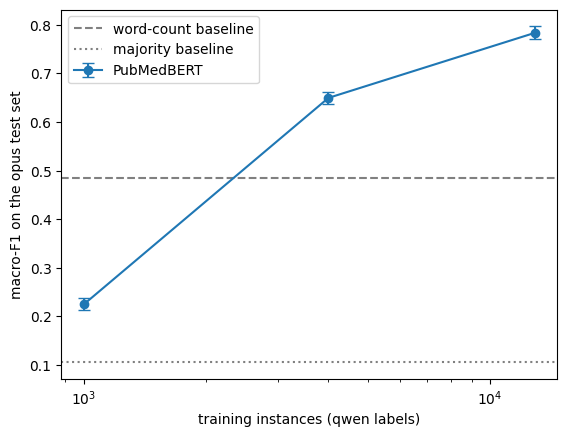

In [20]:
import matplotlib.pyplot as plt

results = pd.DataFrame(rows)
results = results[results['masked'].astype(str) == str(MASK_ENTITIES)]

# mean and spread over the three seeds, per training size
print(results.groupby('n')[['accuracy', 'macro_f1']].agg(['mean', 'std']).round(3))

# F1 of each label per training size (mean over seeds)
label_columns = [c for c in results.columns if c.startswith('f1_')]
print(results.groupby('n')[label_columns].mean().T.round(2))

by_size = results.groupby('n')['macro_f1']
plt.errorbar(by_size.mean().index, by_size.mean(), yerr=by_size.std(), marker='o', capsize=4,
             label='PubMedBERT')
plt.xscale('log')
plt.xlabel('training instances (qwen labels)')
plt.ylabel('macro-F1 on the opus test set')
plt.legend()
plt.show()